In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/subhajitiitmbs/augmented-noise-dataset-artificially/noisy_librispeech/metadata.csv
/kaggle/input/datasets/subhajitiitmbs/augmented-noise-dataset-artificially/noisy_librispeech/augmentation/noise_params.json
/kaggle/input/datasets/subhajitiitmbs/augmented-noise-dataset-artificially/noisy_librispeech/test/1034_121119_1034-121119-0042_brown_snr0.pt
/kaggle/input/datasets/subhajitiitmbs/augmented-noise-dataset-artificially/noisy_librispeech/test/1034_121119_1034-121119-0042_brown_snr0.txt
/kaggle/input/datasets/subhajitiitmbs/augmented-noise-dataset-artificially/noisy_librispeech/test/1034_121119_1034-121119-0042_brown_snr10.pt
/kaggle/input/datasets/subhajitiitmbs/augmented-noise-dataset-artificially/noisy_librispeech/test/1034_121119_1034-121119-0042_brown_snr10.txt
/kaggle/input/datasets/subhajitiitmbs/augmented-noise-dataset-artificially/noisy_librispeech/test/1034_121119_1034-121119-0042_brown_snr20.pt
/kaggle/input/datasets/subhajitiitmbs/augmented-noise-datase

## Wav2Vec2 Training

In [2]:
!pip install transformers accelerate evaluate jiwer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 47.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [evaluate]


### Import libraries and configure the environment

In [3]:
import os
import re
import gc
import json
import random
import warnings

from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import Dataset

from transformers import (
    Wav2Vec2Processor,
    Wav2Vec2ForCTC,
    TrainingArguments,
    Trainer
)

import evaluate

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Dataset configuration
DATA_DIR = Path("/kaggle/input/datasets/subhajitiitmbs/augmented-noise-dataset-artificially/noisy_librispeech")
METADATA_PATH = DATA_DIR / "metadata.csv"

# Model configuration
MODEL_NAME = "facebook/wav2vec2-base-960h"

OUTPUT_DIR = Path("/kaggle/working/wav2vec2_librispeech")

SAMPLE_RATE = 16000

# Training configuration
BATCH_SIZE = 4
GRADIENT_ACCUMULATION_STEPS = 2

LEARNING_RATE = 3e-4
NUM_TRAINING_STEPS = 2000

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


### Load and inspect the metadata

In [4]:
assert METADATA_PATH.exists(), f"Metadata not found: {METADATA_PATH}"

metadata = pd.read_csv(METADATA_PATH)

print("Total metadata entries:", len(metadata))

display(metadata.head())

print("\nAvailable columns:")
print(metadata.columns.tolist())

print("\nSplit distribution:")
print(metadata["split"].value_counts())

if "noise_type" in metadata.columns:
    print("\nNoise distribution:")
    print(metadata["noise_type"].value_counts())

if "snr_db" in metadata.columns:
    print("\nSNR distribution:")
    print(metadata["snr_db"].value_counts())

Total metadata entries: 13000


,audio_id,audio_path,text,duration,original_sample_rate,noise_type,snr_db,split
0,7190_90542_7190-90542-0043_clean,/kaggle/working/noisy_librispeech/train/7190_9...,once or twice the professor gave me a warning ...,15.285,16000,clean,inf,train
1,7190_90542_7190-90542-0043_white_snr20,/kaggle/working/noisy_librispeech/train/7190_9...,once or twice the professor gave me a warning ...,15.285,16000,white,20.0,train
2,7190_90542_7190-90542-0043_white_snr10,/kaggle/working/noisy_librispeech/train/7190_9...,once or twice the professor gave me a warning ...,15.285,16000,white,10.0,train
3,7190_90542_7190-90542-0043_white_snr5,/kaggle/working/noisy_librispeech/train/7190_9...,once or twice the professor gave me a warning ...,15.285,16000,white,5.0,train
4,7190_90542_7190-90542-0043_white_snr0,/kaggle/working/noisy_librispeech/train/7190_9...,once or twice the professor gave me a warning ...,15.285,16000,white,0.0,train



Available columns:
['audio_id', 'audio_path', 'text', 'duration', 'original_sample_rate', 'noise_type', 'snr_db', 'split']

Split distribution:
split
train    9750
test     2600
valid     650
Name: count, dtype: int64

Noise distribution:
noise_type
white    4000
pink     4000
brown    4000
clean    1000
Name: count, dtype: int64

SNR distribution:
snr_db
20.0    3000
5.0     3000
10.0    3000
0.0     3000
inf     1000
Name: count, dtype: int64


### Resolve Audio Paths and clean metadata

In [5]:
from tqdm.auto import tqdm
from pathlib import Path

required_columns = {
    "audio_id",
    "text",
    "split"
}

missing_columns = required_columns - set(metadata.columns)

if missing_columns:
    raise ValueError(
        f"Missing required metadata columns: {missing_columns}"
    )


def resolve_audio_path(row):

    stored_path = row.get("audio_path", None)

    if isinstance(stored_path, str) and stored_path.strip():

        path = Path(stored_path)

        if path.exists():
            return str(path)

    candidate = DATA_DIR / f"{row['audio_id']}.pt"

    if candidate.exists():
        return str(candidate)

    matches = list(
        DATA_DIR.rglob(f"{row['audio_id']}.pt")
    )

    if matches:
        return str(matches[0])

    return None


# Resolve audio paths with a live progress bar
resolved_paths = []

for _, row in tqdm(
    metadata.iterrows(),
    total=len(metadata),
    desc="Resolving audio paths",
    unit="record"
):
    resolved_path = resolve_audio_path(row)
    resolved_paths.append(resolved_path)

metadata["audio_path_resolved"] = resolved_paths


# Normalize text
metadata["text"] = (
    metadata["text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Normalize split names
metadata["split"] = (
    metadata["split"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.strip()
)

metadata["split"] = metadata["split"].replace({
    "valid": "validation",
    "val": "validation"
})


# Filter usable records
metadata = metadata[
    metadata["audio_path_resolved"].notna()
    &
    (metadata["text"] != "")
    &
    metadata["split"].isin([
        "train",
        "validation",
        "test"
    ])
].copy()

metadata = metadata.reset_index(drop=True)


print("\n========== Metadata Processing Summary ==========")
print("Total records processed:", len(resolved_paths))
print("Usable audio samples:", len(metadata))
print("\nSplit distribution:")
print(metadata["split"].value_counts())
print("==================================================")

display(metadata.head())

Resolving audio paths:   0%|          | 0/13000 [00:00<?, ?record/s]


========== Metadata Processing Summary ==========
Total records processed: 13000
Usable audio samples: 13000

Split distribution:
split
train         9750
test          2600
validation     650
Name: count, dtype: int64


,audio_id,audio_path,text,duration,original_sample_rate,noise_type,snr_db,split,audio_path_resolved
0,7190_90542_7190-90542-0043_clean,/kaggle/working/noisy_librispeech/train/7190_9...,once or twice the professor gave me a warning ...,15.285,16000,clean,inf,train,/kaggle/input/datasets/subhajitiitmbs/augmente...
1,7190_90542_7190-90542-0043_white_snr20,/kaggle/working/noisy_librispeech/train/7190_9...,once or twice the professor gave me a warning ...,15.285,16000,white,20.0,train,/kaggle/input/datasets/subhajitiitmbs/augmente...
2,7190_90542_7190-90542-0043_white_snr10,/kaggle/working/noisy_librispeech/train/7190_9...,once or twice the professor gave me a warning ...,15.285,16000,white,10.0,train,/kaggle/input/datasets/subhajitiitmbs/augmente...
3,7190_90542_7190-90542-0043_white_snr5,/kaggle/working/noisy_librispeech/train/7190_9...,once or twice the professor gave me a warning ...,15.285,16000,white,5.0,train,/kaggle/input/datasets/subhajitiitmbs/augmente...
4,7190_90542_7190-90542-0043_white_snr0,/kaggle/working/noisy_librispeech/train/7190_9...,once or twice the professor gave me a warning ...,15.285,16000,white,0.0,train,/kaggle/input/datasets/subhajitiitmbs/augmente...


### Verify Recording Level Data Splits

In [6]:
AUGMENTATION_SUFFIX = re.compile(
    r"_(?:clean|(?:white|pink|brown)_snr-?\d+(?:\.\d+)?)$",
    re.IGNORECASE
)


def get_source_id(audio_id):

    return AUGMENTATION_SUFFIX.sub(
        "",
        str(audio_id)
    )


metadata["source_id"] = metadata["audio_id"].apply(
    get_source_id
)

split_counts = metadata.groupby(
    "source_id"
)["split"].nunique()

leaked_sources = split_counts[
    split_counts > 1
]

if len(leaked_sources) > 0:

    raise ValueError(
        "Data leakage detected! Some original recordings "
        "occur in multiple splits.\n"
        f"Examples: {leaked_sources.index[:10].tolist()}"
    )

print("Recording-level split verification passed.")

print(
    "Unique original recordings:",
    metadata["source_id"].nunique()
)

Recording-level split verification passed.
Unique original recordings: 1000


### Create Train, Test and Validation Dataset

In [7]:
train_df = metadata[
    metadata["split"] == "train"
].reset_index(drop=True)

valid_df = metadata[
    metadata["split"] == "validation"
].reset_index(drop=True)

test_df = metadata[
    metadata["split"] == "test"
].reset_index(drop=True)


print("Training samples:", len(train_df))
print("Validation samples:", len(valid_df))
print("Testing samples:", len(test_df))


assert len(train_df) > 0
assert len(valid_df) > 0
assert len(test_df) > 0

Training samples: 9750
Validation samples: 650
Testing samples: 2600


### Initialize Model

In [8]:
processor = Wav2Vec2Processor.from_pretrained(
    MODEL_NAME
)

model = Wav2Vec2ForCTC.from_pretrained(
    MODEL_NAME,
    ctc_loss_reduction="mean",
    pad_token_id=processor.tokenizer.pad_token_id
)

print("Model loaded successfully.")

print("Vocabulary size:",
      len(processor.tokenizer))

print("Padding token:",
      processor.tokenizer.pad_token)

print("Sampling rate:",
      processor.feature_extractor.sampling_rate)

print("Model parameters:",
      sum(p.numel() for p in model.parameters()))

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully.
Vocabulary size: 32
Padding token: <pad>
Sampling rate: 16000
Model parameters: 94396320


### Normalize Transcripts

In [9]:
def normalize_transcript(text):

    text = str(text).upper()

    text = re.sub(
        r"[^A-Z' ]",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


for dataframe in [
    train_df,
    valid_df,
    test_df
]:

    dataframe["normalized_text"] = (
        dataframe["text"]
        .apply(normalize_transcript)
    )


display(
    train_df[
        ["text", "normalized_text"]
    ].head(10)
)

,text,normalized_text
0,once or twice the professor gave me a warning ...,ONCE OR TWICE THE PROFESSOR GAVE ME A WARNING ...
1,once or twice the professor gave me a warning ...,ONCE OR TWICE THE PROFESSOR GAVE ME A WARNING ...
2,once or twice the professor gave me a warning ...,ONCE OR TWICE THE PROFESSOR GAVE ME A WARNING ...
3,once or twice the professor gave me a warning ...,ONCE OR TWICE THE PROFESSOR GAVE ME A WARNING ...
4,once or twice the professor gave me a warning ...,ONCE OR TWICE THE PROFESSOR GAVE ME A WARNING ...
5,once or twice the professor gave me a warning ...,ONCE OR TWICE THE PROFESSOR GAVE ME A WARNING ...
6,once or twice the professor gave me a warning ...,ONCE OR TWICE THE PROFESSOR GAVE ME A WARNING ...
7,once or twice the professor gave me a warning ...,ONCE OR TWICE THE PROFESSOR GAVE ME A WARNING ...
8,once or twice the professor gave me a warning ...,ONCE OR TWICE THE PROFESSOR GAVE ME A WARNING ...
9,once or twice the professor gave me a warning ...,ONCE OR TWICE THE PROFESSOR GAVE ME A WARNING ...


### Load the saved audio tensors

In [10]:
def load_waveform(audio_path):

    try:

        waveform = torch.load(
            audio_path,
            map_location="cpu",
            weights_only=True
        )

    except TypeError:

        waveform = torch.load(
            audio_path,
            map_location="cpu"
        )

    except Exception:

        waveform = torch.load(
            audio_path,
            map_location="cpu",
            weights_only=False
        )


    if isinstance(waveform, dict):

        for key in [
            "waveform",
            "audio",
            "input_values",
            "samples"
        ]:

            if key in waveform:

                waveform = waveform[key]
                break


    waveform = torch.as_tensor(
        waveform
    ).float().squeeze()


    # Convert stereo to mono
    if waveform.ndim == 2:

        if waveform.shape[0] <= 8:

            waveform = waveform.mean(dim=0)

        else:

            waveform = waveform.mean(dim=1)


    if waveform.ndim != 1:

        raise ValueError(
            f"Expected mono waveform, got {waveform.shape}"
        )


    waveform = torch.nan_to_num(waveform)

    return waveform.numpy().astype(np.float32)

### Create Pytorch Dataset Class

In [11]:
class LibriSpeechDataset(torch.utils.data.Dataset):

    def __init__(self, metadata, processor):
        self.metadata = metadata.reset_index(drop=True)
        self.processor = processor

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, index):

        row = self.metadata.iloc[index]

        audio_path = row["audio_path_resolved"]
        text = row["text"]

        # Load waveform
        try:
            waveform = torch.load(
                audio_path,
                map_location="cpu",
                weights_only=True
            )
        except TypeError:
            waveform = torch.load(
                audio_path,
                map_location="cpu"
            )

        # Convert to tensor if necessary
        if not isinstance(waveform, torch.Tensor):
            waveform = torch.tensor(waveform)

        # Ensure mono audio
        if waveform.ndim == 2:
            waveform = waveform.mean(dim=0)

        waveform = waveform.float().squeeze()

        # Extract audio features
        input_values = self.processor(
            waveform.numpy(),
            sampling_rate=16000,
            return_tensors="pt"
        ).input_values.squeeze(0)

        # Normalize transcript
        text = str(text).upper()

        # Tokenize transcript
        labels = self.processor.tokenizer(
            text,
            return_tensors="pt"
        ).input_ids.squeeze(0)

        return {
            "input_values": input_values,
            "labels": labels
        }

### Create the CTC data collator

In [12]:
class DataCollatorCTCWithPadding:

    def __init__(self, processor, padding=True):
        self.processor = processor
        self.padding = padding

    def __call__(self, features):

        # Separate audio inputs and transcript labels
        input_features = [
            {"input_values": feature["input_values"]}
            for feature in features
        ]

        label_features = [
            {"input_ids": feature["labels"].tolist()}
            for feature in features
        ]

        # Pad audio inputs
        batch = self.processor.feature_extractor.pad(
            input_features,
            padding=self.padding,
            return_tensors="pt"
        )

        # Pad transcript labels using the tokenizer directly
        labels_batch = self.processor.tokenizer.pad(
            label_features,
            padding=self.padding,
            return_tensors="pt"
        )

        # Replace label padding tokens with -100
        labels = labels_batch["input_ids"].masked_fill(
            labels_batch["attention_mask"].ne(1),
            -100
        )

        batch["labels"] = labels

        return batch

### Initialize datasets and inspect a sample

In [13]:
train_dataset = LibriSpeechDataset(
    train_df,
    processor
)

valid_dataset = LibriSpeechDataset(
    valid_df,
    processor
)

test_dataset = LibriSpeechDataset(
    test_df,
    processor
)


data_collator = DataCollatorCTCWithPadding(
    processor=processor,
    padding=True
)


sample = train_dataset[0]

print(
    "Input waveform shape:",
    sample["input_values"].shape
)

print(
    "Label shape:",
    sample["labels"].shape
)

print(
    "Decoded transcript:",
    processor.decode(sample["labels"])
)

Input waveform shape: torch.Size([244560])
Label shape: torch.Size([258])
Decoded transcript: ONCE OR TWICE THE PROFESOR GAVE ME A WARNING GESTURE BUT HE DID NOT SPEAK HE HAD EVIDENTLY SOME DEFINITE GOAL AND I WAS CONSCIOUS OF EXCITEMENT AS I FOLOWED HIM FOR AN HOUR OR MORE HE TURNED THIS WAY AND THAT EXPLORING EVERY LITLE RAVINE HE COULD DISCOVER


In [14]:
features = [
    train_dataset[i]
    for i in range(min(2, len(train_dataset)))
]

batch = data_collator(features)

for key, value in batch.items():
    print(
        key,
        value.shape,
        value.dtype
    )

print("\nDecoded labels:")

for labels in batch["labels"]:
    valid_labels = labels[labels != -100]

    print(
        processor.tokenizer.decode(valid_labels)
    )

input_values torch.Size([2, 244560]) torch.float32
labels torch.Size([2, 258]) torch.int64

Decoded labels:
ONCE OR TWICE THE PROFESOR GAVE ME A WARNING GESTURE BUT HE DID NOT SPEAK HE HAD EVIDENTLY SOME DEFINITE GOAL AND I WAS CONSCIOUS OF EXCITEMENT AS I FOLOWED HIM FOR AN HOUR OR MORE HE TURNED THIS WAY AND THAT EXPLORING EVERY LITLE RAVINE HE COULD DISCOVER
ONCE OR TWICE THE PROFESOR GAVE ME A WARNING GESTURE BUT HE DID NOT SPEAK HE HAD EVIDENTLY SOME DEFINITE GOAL AND I WAS CONSCIOUS OF EXCITEMENT AS I FOLOWED HIM FOR AN HOUR OR MORE HE TURNED THIS WAY AND THAT EXPLORING EVERY LITLE RAVINE HE COULD DISCOVER


### Define evaluation metrics

In [15]:
wer_metric = evaluate.load("wer")

cer_metric = evaluate.load("cer")


def compute_metrics(pred):

    pred_logits = pred.predictions

    if isinstance(pred_logits, tuple):

        pred_logits = pred_logits[0]


    # Greedy decoding
    pred_ids = np.argmax(
        pred_logits,
        axis=-1
    )


    label_ids = pred.label_ids.copy()

    label_ids[
        label_ids == -100
    ] = processor.tokenizer.pad_token_id


    predictions = processor.batch_decode(
        pred_ids
    )

    references = processor.batch_decode(
        label_ids,
        group_tokens=False
    )


    wer = wer_metric.compute(
        predictions=predictions,
        references=references
    )

    cer = cer_metric.compute(
        predictions=predictions,
        references=references
    )


    return {
        "wer": wer,
        "cer": cer
    }

### Configure training parameters

In [16]:
# Model training configuration

BATCH_SIZE = 2
GRADIENT_ACCUMULATION_STEPS = 4

LEARNING_RATE = 3e-4
MAX_STEPS = 2000

WARMUP_STEPS = 500
WEIGHT_DECAY = 0.005

EVAL_STEPS = 250
SAVE_STEPS = 250
LOGGING_STEPS = 25

NUM_WORKERS = 2

print("Training configuration initialized.")

Training configuration initialized.


In [17]:
training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR),

    # Batch configuration
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,

    # Optimization
    learning_rate=LEARNING_RATE,
    warmup_steps=500,
    max_steps=MAX_STEPS,
    weight_decay=0.005,

    # Evaluation and checkpointing
    eval_strategy="steps",
    eval_steps=250,
    save_steps=250,
    logging_steps=25,
    save_total_limit=2,

    # Performance
    fp16=torch.cuda.is_available(),
    gradient_checkpointing=True,

    # Other settings
    report_to="none",
    dataloader_num_workers=2,
    dataloader_pin_memory=True,

    # Best checkpoint
    load_best_model_at_end=True,
    metric_for_best_model="wer",
    greater_is_better=False,
)


print(training_args)

TrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,
bf16_full_eval=False,
data_seed=None,
dataloader_drop_last=False,
dataloader_in_order=True,
dataloader_multiprocessing_context=None,
dataloader_num_workers=2,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_static_graph=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_eval=True,
do_predict=False,
do_train=False,
enable_jit_checkpoint=False,
eval_accumulation_steps=None,
eval_delay=0,
eval_do_concat_batches=True,
eval_on_start

### Initialize the trainer

In [18]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

### Train the Wav2Vec2 model

In [19]:
training_result = trainer.train()

print("Training completed.")

print(training_result)

Step,Training Loss,Validation Loss,Wer,Cer
250,0.000000,1.683521,0.264227,0.169290
500,0.000000,1.683521,0.264227,0.169290
750,0.000000,1.683521,0.264227,0.169290
1000,0.000000,1.683521,0.264227,0.169290
1250,0.000000,1.683521,0.264227,0.169290
1500,0.000000,1.683521,0.264227,0.169290
1750,0.000000,1.683521,0.264227,0.169290
2000,0.000000,1.683521,0.264227,0.169290


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training completed.
TrainOutput(global_step=2000, training_loss=0.0, metrics={'train_runtime': 6191.9247, 'train_samples_per_second': 5.168, 'train_steps_per_second': 0.323, 'total_flos': 4.457395870630452e+18, 'train_loss': 0.0, 'epoch': 3.2789171452009844})


In [20]:
FINAL_MODEL_DIR = OUTPUT_DIR / "final_model"

FINAL_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

trainer.save_model(
    str(FINAL_MODEL_DIR)
)

processor.save_pretrained(
    str(FINAL_MODEL_DIR)
)

print("Model saved at:", FINAL_MODEL_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved at: /kaggle/working/wav2vec2_librispeech/final_model


### Evaluate on the held-out test set

In [21]:
test_output = trainer.predict(
    test_dataset
)


test_logits = test_output.predictions

if isinstance(test_logits, tuple):

    test_logits = test_logits[0]


predicted_ids = np.argmax(
    test_logits,
    axis=-1
)


label_ids = test_output.label_ids.copy()

label_ids[
    label_ids == -100
] = processor.tokenizer.pad_token_id


predictions = processor.batch_decode(
    predicted_ids
)

references = processor.batch_decode(
    label_ids,
    group_tokens=False
)


test_wer = wer_metric.compute(
    predictions=predictions,
    references=references
)

test_cer = cer_metric.compute(
    predictions=predictions,
    references=references
)


print(f"Test WER: {test_wer:.4f}")

print(f"Test WER (%): {test_wer * 100:.2f}%")

print(f"Test CER: {test_cer:.4f}")

print(f"Test CER (%): {test_cer * 100:.2f}%")

Test WER: 0.2512
Test WER (%): 25.12%
Test CER: 0.1589
Test CER (%): 15.89%


### Save the transcription results

In [22]:
results_df = test_df[
    [
        "audio_id",
        "text",
        "normalized_text"
    ]
].copy()


results_df["prediction"] = predictions


if "noise_type" in test_df.columns:

    results_df["noise_type"] = (
        test_df["noise_type"].values
    )


if "snr_db" in test_df.columns:

    results_df["snr_db"] = (
        test_df["snr_db"].values
    )


results_df.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False
)


metrics = {
    "test_wer": float(test_wer),
    "test_cer": float(test_cer)
}


with open(
    OUTPUT_DIR / "test_metrics.json",
    "w"
) as f:

    json.dump(
        metrics,
        f,
        indent=4
    )


display(results_df.head(20))

,audio_id,text,normalized_text,prediction,noise_type,snr_db
0,4640_19187_4640-19187-0001_clean,and an embryo compared to the two colossal bar...,AND AN EMBRYO COMPARED TO THE TWO COLOSSAL BAR...,AT AN EMBRYO COMPARED TO THE TWO COLOSSAL BARR...,clean,inf
1,4640_19187_4640-19187-0001_white_snr20,and an embryo compared to the two colossal bar...,AND AN EMBRYO COMPARED TO THE TWO COLOSSAL BAR...,AT AN EMBRYO COMPARED TO THE TWO COLOSSAL BARR...,white,20.0
2,4640_19187_4640-19187-0001_white_snr10,and an embryo compared to the two colossal bar...,AND AN EMBRYO COMPARED TO THE TWO COLOSSAL BAR...,AT AN IMBRYO COMPARITO THE TOO COLOSSAL VERITY...,white,10.0
3,4640_19187_4640-19187-0001_white_snr5,and an embryo compared to the two colossal bar...,AND AN EMBRYO COMPARED TO THE TWO COLOSSAL BAR...,AT AN EMBIO COMPERITY THE TO PFOF EVERITY I E...,white,5.0
4,4640_19187_4640-19187-0001_white_snr0,and an embryo compared to the two colossal bar...,AND AN EMBRYO COMPARED TO THE TWO COLOSSAL BAR...,AND IN ENVY O TE VERE TE IE TOO TEVERE TE TE E...,white,0.0
5,4640_19187_4640-19187-0001_pink_snr20,and an embryo compared to the two colossal bar...,AND AN EMBRYO COMPARED TO THE TWO COLOSSAL BAR...,AT AN EMBRYO COMPARED TO THE TWO COLOSSAL BARR...,pink,20.0
6,4640_19187_4640-19187-0001_pink_snr10,and an embryo compared to the two colossal bar...,AND AN EMBRYO COMPARED TO THE TWO COLOSSAL BAR...,AT AN EMBRYO COMPARED TO THE TWO COLOSSAL BARR...,pink,10.0
7,4640_19187_4640-19187-0001_pink_snr5,and an embryo compared to the two colossal bar...,AND AN EMBRYO COMPARED TO THE TWO COLOSSAL BAR...,AT AN EMBRYO COMPARETO THE TWO COLOSSFORBARITY...,pink,5.0
8,4640_19187_4640-19187-0001_pink_snr0,and an embryo compared to the two colossal bar...,AND AN EMBRYO COMPARED TO THE TWO COLOSSAL BAR...,AND IN ENVY OFOPERIT TE FOFORVERITTO FO A YUS ...,pink,0.0
9,4640_19187_4640-19187-0001_brown_snr20,and an embryo compared to the two colossal bar...,AND AN EMBRYO COMPARED TO THE TWO COLOSSAL BAR...,AT AN EMBRYO COMPARED TO THE TWO COLOSSAL BARR...,brown,20.0


### Evaluate performance by noise type and SNR

In [23]:
condition_results = []


if {
    "noise_type",
    "snr_db"
}.issubset(results_df.columns):

    for (
        noise_type,
        snr_db
    ), group in results_df.groupby(
        ["noise_type", "snr_db"],
        dropna=False
    ):

        condition_wer = wer_metric.compute(

            predictions=group["prediction"].tolist(),

            references=group["normalized_text"].tolist()
        )


        condition_cer = cer_metric.compute(

            predictions=group["prediction"].tolist(),

            references=group["normalized_text"].tolist()
        )


        condition_results.append({

            "noise_type": noise_type,

            "snr_db": snr_db,

            "num_samples": len(group),

            "wer": condition_wer,

            "cer": condition_cer
        })


    condition_df = pd.DataFrame(
        condition_results
    )


    display(condition_df)


    condition_df.to_csv(

        OUTPUT_DIR / "wer_by_noise_condition.csv",

        index=False
    )

else:

    print(
        "Noise type or SNR metadata columns are unavailable."
    )

,noise_type,snr_db,num_samples,wer,cer
0,brown,0.0,200,0.024914,0.005566
1,brown,5.0,200,0.025057,0.005620
2,brown,10.0,200,0.024914,0.005404
3,brown,20.0,200,0.023625,0.005107
4,clean,inf,200,0.024341,0.005161
5,pink,0.0,200,0.813574,0.604907
6,pink,5.0,200,0.371277,0.194007
7,pink,10.0,200,0.089920,0.032046
8,pink,20.0,200,0.026632,0.006215
9,white,0.0,200,0.941581,0.730903


### Plot WER across noise conditions

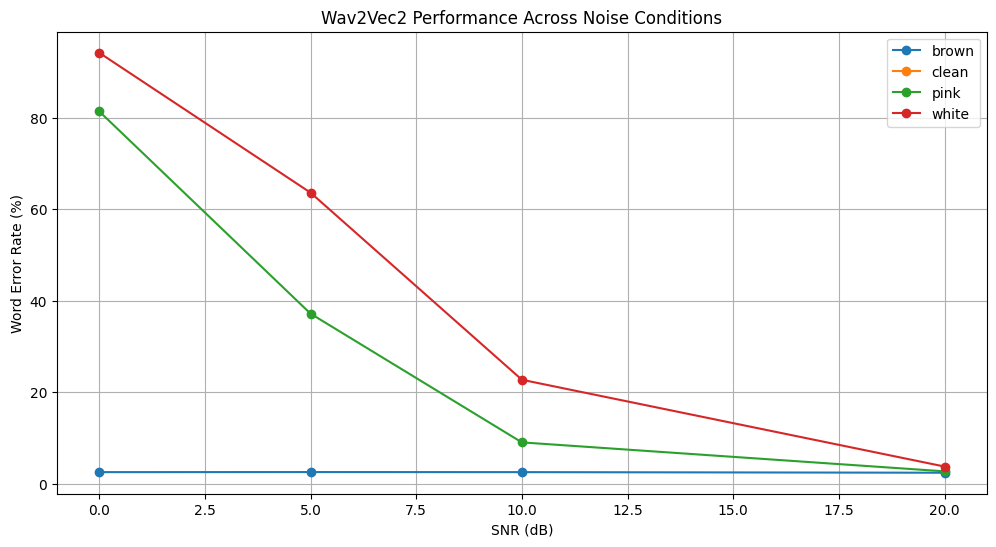

In [24]:
import matplotlib.pyplot as plt

if not condition_df.empty:

    plt.figure(figsize=(12, 6))

    for noise_type in condition_df["noise_type"].dropna().unique():

        subset = condition_df[
            condition_df["noise_type"] == noise_type
        ].copy()

        subset["snr_numeric"] = pd.to_numeric(
            subset["snr_db"],
            errors="coerce"
        )

        subset = subset.sort_values(
            "snr_numeric"
        )

        plt.plot(
            subset["snr_numeric"],
            subset["wer"] * 100,
            marker="o",
            label=str(noise_type)
        )


    plt.xlabel("SNR (dB)")

    plt.ylabel("Word Error Rate (%)")

    plt.title("Wav2Vec2 Performance Across Noise Conditions")

    plt.legend()

    plt.grid(True)

    plt.show()

### Transcribe an individual audio file

In [25]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = trainer.model.to(device)

model.eval()


def transcribe_audio(audio_path):

    waveform = load_waveform(
        audio_path
    )


    inputs = processor(
        waveform,

        sampling_rate=SAMPLE_RATE,

        return_tensors="pt",

        padding=True
    )


    input_values = inputs.input_values.to(
        device
    )


    with torch.no_grad():

        logits = model(
            input_values
        ).logits


    predicted_ids = torch.argmax(
        logits,
        dim=-1
    )


    transcription = processor.batch_decode(
        predicted_ids
    )[0]


    return transcription.strip()

In [26]:
sample_row = test_df.iloc[0]

audio_path = sample_row["audio_path_resolved"]

predicted_transcription = transcribe_audio(
    audio_path
)

print("Audio ID:", sample_row["audio_id"])

print("\nReference:")
print(sample_row["normalized_text"])

print("\nPrediction:")
print(predicted_transcription)

Audio ID: 4640_19187_4640-19187-0001_clean

Reference:
AND AN EMBRYO COMPARED TO THE TWO COLOSSAL BARRICADES WHICH WE HAVE JUST SKETCHED BUT IT WAS FORMIDABLE FOR THAT EPOCH

Prediction:
AT AN EMBRYO COMPARED TO THE TWO COLOSSAL BARRICADES WHICH WE HAVE JUST SKETCHED BUT IT WAS FORMIDABLE FOR THAT EPOCH


### Save the experimental summary

In [27]:
experiment_summary = {

    "model": MODEL_NAME,

    "sampling_rate": SAMPLE_RATE,

    "train_samples": len(train_dataset),

    "validation_samples": len(valid_dataset),

    "test_samples": len(test_dataset),

    "batch_size": BATCH_SIZE,

    "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,

    "learning_rate": LEARNING_RATE,

    "training_steps": NUM_TRAINING_STEPS,

    "test_wer": float(test_wer),

    "test_cer": float(test_cer),

    "output_directory": str(OUTPUT_DIR)
}


with open(
    OUTPUT_DIR / "experiment_summary.json",
    "w"
) as f:

    json.dump(
        experiment_summary,
        f,
        indent=4
    )


print(json.dumps(
    experiment_summary,
    indent=4
))

{
    "model": "facebook/wav2vec2-base-960h",
    "sampling_rate": 16000,
    "train_samples": 9750,
    "validation_samples": 650,
    "test_samples": 2600,
    "batch_size": 2,
    "gradient_accumulation_steps": 4,
    "learning_rate": 0.0003,
    "training_steps": 2000,
    "test_wer": 0.25118953211736716,
    "test_cer": 0.15893431327514929,
    "output_directory": "/kaggle/working/wav2vec2_librispeech"
}
